# Monte Carlo Stock Price Simulation

A stock starts at 100. Each day its return is a random draw from a bell curve (mean 0.04%, standard deviation 1%). I simulated 1,000 possible years of 252 trading days each, and asked: how often does the stock lose 10% or more?

**Key findings**
- Daily returns multiply, so each day's price is the previous price times (1 + return).
- The average final price is about 110.6, which matches the theory 100 × 1.0004^252.
- About 12% of simulated years end at 90 or below.
- Final prices are right-skewed because returns multiply, not add.
- Taking the log turns the product into a sum, so by the Central Limit Theorem the log of the final price is a bell curve (lognormal model).

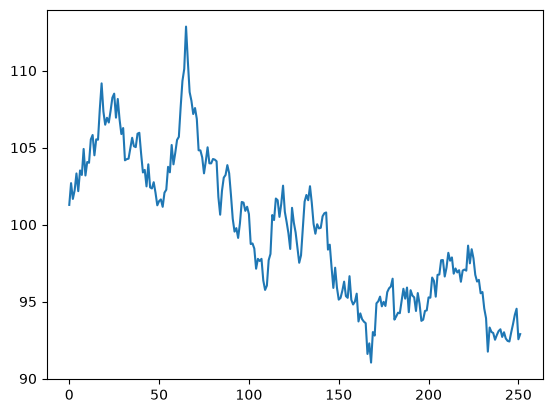

In [7]:
import numpy as np
import matplotlib.pyplot as plt
daily_returns = np.random.normal(0.0004, 0.01, size=(252))
start_price = 100
prices = start_price * np.cumprod(1 + daily_returns)

#print(prices)
plt.plot(prices)
plt.show()

In [8]:
n_years = 1000
daily_returns = np.random.normal(0.0004, 0.01, size=(n_years, 252))
prices = start_price * np.cumprod(1 + daily_returns, axis=1)
final_prices = prices[:, -1]
print(final_prices.mean())

110.62804647251448


In [9]:
n_years = 1000
daily_returns = np.random.normal(0.0004, 0.01, size=(n_years, 252))
prices = start_price * np.cumprod(1 + daily_returns, axis=1)
final_prices = prices[:, -1]
print("Theory:", start_price * 1.0004 **252)
print("Simulation:", final_prices.mean())

Theory: 110.60331166510937
Simulation: 110.29094620863181


In [10]:
bad_years = final_prices < 90
print("Number of bad_years:", bad_years.sum())
print("Chance of losing 10% money:", bad_years.mean())


Number of bad_years: 104
Chance of losing 10% money: 0.104


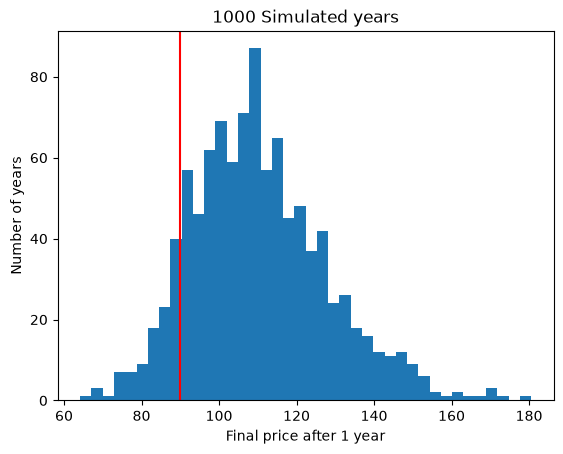

In [11]:
plt.hist(final_prices, bins=40)
plt.axvline(90, color="red")
plt.xlabel("Final price after 1 year")
plt.ylabel("Number of years")
plt.title("1000 Simulated years")
plt.savefig("final_prices_hist", dpi=150)
plt.show()

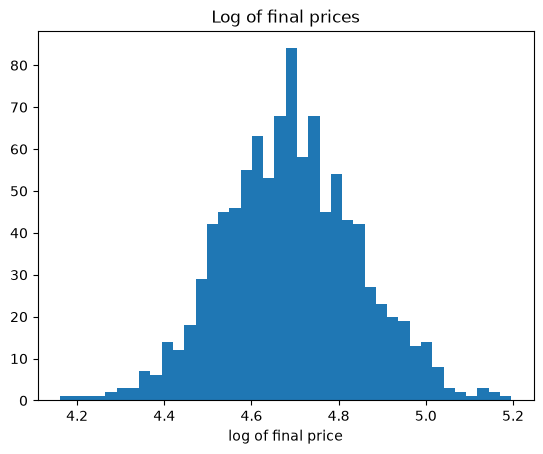

In [12]:
plt.hist(np.log(final_prices), bins=40)
plt.xlabel("log of final price")
plt.title("Log of final prices")
plt.show()